Explicit Scheme Heat Equation Finite Difference Method on a 1D Rod, the material is completely homogeneous

$u_t = D u_{xx}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Parameters

time = 1, time_step = 0.25, step_size = 0.25

Length = 1

Dirchelet Boundary Conditions: $U(0, t) = 1$

Diffusivity Constant: D = 5

Initial Conditions: $U(x, 0) = 0$

In [2]:
Length = 1
time_step = 0.25
step_size = 0.25
D = 0.1

In [3]:
r = (D * time_step) / (step_size**2)
r

0.4

In [4]:
# Numerical Stability
b = (step_size**2)/(2 * D)
b

0.3125

In [5]:
time_step <= b

True

In [6]:
n = 1

In [7]:
#x_range = np.arange(0, 1 + step_size, step_size)
x_range = np.arange(0, Length + step_size, step_size)
x_range

array([0.  , 0.25, 0.5 , 0.75, 1.  ])

In [8]:
t_range = np.arange(0, Length + time_step, time_step)
t_range

array([0.  , 0.25, 0.5 , 0.75, 1.  ])

In [9]:
x_len, t_len = len(x_range), len(t_range)

In [10]:
grid = np.zeros((x_len, t_len))
grid

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]])

Apply Dirichelet Boundary Conditions

In [11]:
grid[:,0] = np.sin(n * np.pi * x_range)
#grid[:, 0] = 10
#grid[0, :] = 2
#grid[-1, :] = 2
grid

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [7.07106781e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [1.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [7.07106781e-01, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [1.22464680e-16, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00]])

for i in range(1, x_len - 1):
    print(i)

Neumann Values
$\frac{\partial u(0, t)}{\partial x} = g_1$
\\\\
$\frac{\partial u(L, t)}{\partial x} = g_2$

In [12]:
g1 = 0
g2 = 0

In [13]:
for j in range(0, t_len - 1):
    #grid[0, j + 1] = 2 * r * grid[1, j + 1] - r * g1 * 2 * (step_size) + (1 - 2 * r) * grid[0, j]
    #for i in range(1, x_len - 1):
    #Neumann Boundary Conditions
    
    grid[1:-1, j + 1] = r * (grid[2:, j] + grid[:-2, j]) + (1 - 2 * r) * grid[1:-1, j]
    
    
    grid[0, j + 1] = (2 * r * grid[1, j + 1]) - (r * g1 * 2 * (step_size)) + (1 - 2 * r) * grid[0, j]
    
    
    grid[-1, j + 1] = 2 * r * grid[-2, j + 1] + (r * g2 * 2 * (step_size)) + (1 - 2 * r) * grid[-1, j]
    #print(i, j)
    #grid[-1, j + 1] = 2 * r * grid[-2, j + 1] + r * g2 * 2 * (step_size) + (1 - 2 * r) * grid[-1, j]
grid.round(7)

array([[0.       , 0.4331371, 0.556878 , 0.5712344, 0.5770154],
       [0.7071068, 0.5414214, 0.5878133, 0.5748235, 0.5784607],
       [1.       , 0.7656854, 0.5862742, 0.5875055, 0.5773599],
       [0.7071068, 0.5414214, 0.5878133, 0.5748235, 0.5784607],
       [0.       , 0.4331371, 0.556878 , 0.5712344, 0.5770154]])

matrix = np.zeros((x_len, t_len))

for j in range(t_len):
    for i in range(t_len):
        matrix[i, j] = np.sin(x_range[i] * np.pi) * np.exp(-np.pi**2 * D * t_range[j])

matrix.round(7)

In [14]:
matrix = np.zeros((x_len, t_len))

for j in range(t_len):
    for i in range(x_len):
        matrix[i, j] = np.sin(n * x_range[i] * np.pi) * np.exp(-np.pi**2 * D * t_range[j] * (n ** 2))

matrix.round(7)

array([[0.       , 0.       , 0.       , 0.       , 0.       ],
       [0.7071068, 0.5524935, 0.4316873, 0.3372962, 0.2635442],
       [1.       , 0.7813437, 0.610498 , 0.4770088, 0.3727078],
       [0.7071068, 0.5524935, 0.4316873, 0.3372962, 0.2635442],
       [0.       , 0.       , 0.       , 0.       , 0.       ]])

In [15]:
frob_norm = np.linalg.norm(grid - matrix, 'fro')
frob_norm

np.float64(1.6519854497325717)

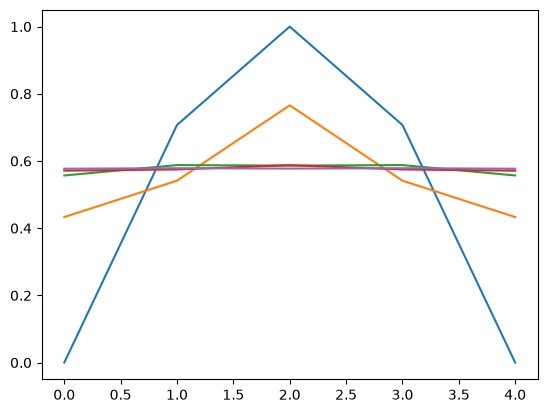

In [16]:
plt.plot(grid)